# Setup

In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels
from Util.pulltest_util import get_axis_velocity
from scipy.signal import find_peaks

In [2]:
recording_name = 'tug1'
filename=os.path.join('data', recording_name, recording_name+'_stereo.npz')
keypoints, labels = load_keypoints_and_labels(filename=filename)
print(keypoints.shape)

loaded data from: data\tug1\tug1_stereo.npz with keys: ['labels', 'keypoints']
(4463, 19, 3)


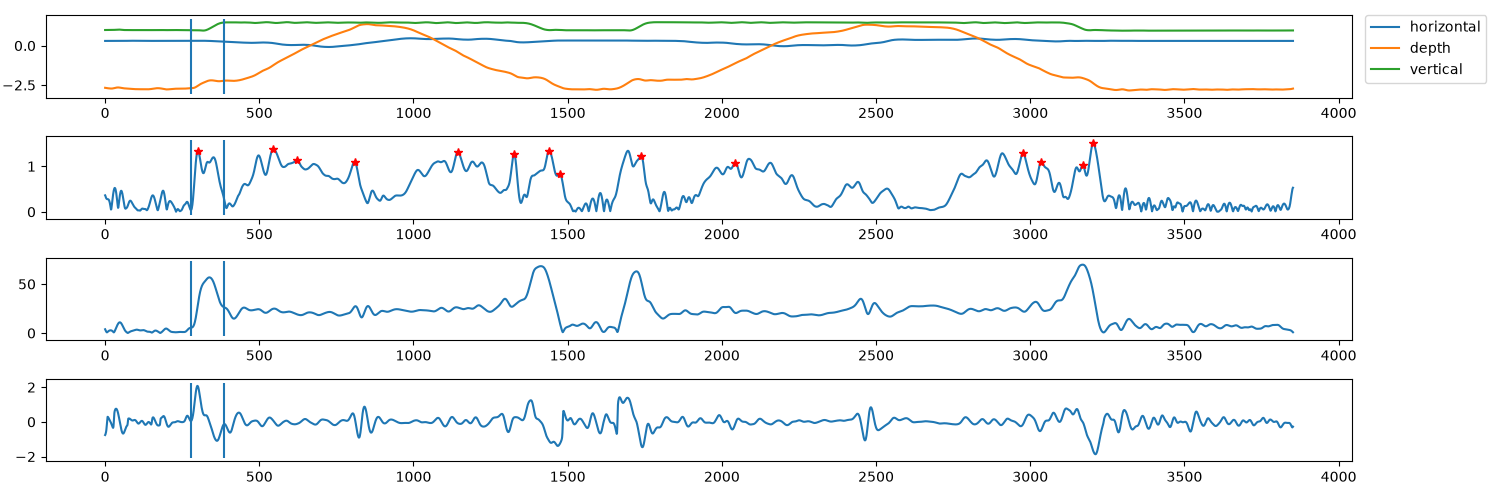

In [70]:
cut_1 = 610
baseline_end = 250
fps = 100
mid_shoulder = keypoints[cut_1:, labels.index('mid_shoulder'),:]

delta_t = 1 / fps  # frames/sec
position = mid_shoulder  # point, meters
velocity = np.gradient(position, delta_t, axis=0)  # vector, m/s
velocity_magnitude = np.linalg.norm(velocity, axis=1)  # scalar


min_peak_height = 0.75
min_peak_distance = 10
peaks, _ = find_peaks(velocity_magnitude, height=0.75, threshold=0.001)


plt.close('all')
fig, axs = plt.subplots(4,1,figsize=(15,5))
axs[0].plot(mid_shoulder, label=['horizontal','depth','vertical'])
axs[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

axs[1].plot(velocity_magnitude)
axs[1].plot(peaks, velocity_magnitude[peaks], 'r*')

axs[2].plot(trunk_angle)
axs[3].plot(trunk_angle_change)

for ax in axs:
    y_min, y_max = ax.get_ylim()
    ax.vlines(280, y_min, y_max)
    ax.vlines(385, y_min, y_max)

plt.tight_layout()

In [69]:
from Util.util import angle_between_vectors

trunk = keypoints[cut_1:,labels.index("mid_shoulder"),:] - keypoints[cut_1:, labels.index("mid_hip"),:]
baseline_trunk = np.nanmean(trunk[:250], axis=0)
trunk_angle = np.array([angle_between_vectors(trunk_vector, baseline_trunk) for trunk_vector in trunk])
trunk_angle_change = np.gradient(trunk_angle)